# Analyse

Le fichier `erp_facilities.csv` contient : entrepôts, hubs de transfert, points de livraison cliniques ou de laboratoire, dépôts de terrain et bureaux. Pour chaque site on a son nom, sa catégorie, son exploitant, son adresse, sa région, ses coordonnées GPS, sa date d'ouverture, son statut et ses capacités de stockage. Les réceptions, les expéditions, les commandes et les inventaires y font référence par facility_code.

---
##  Configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Racine du projet = le premier dossier parent qui contient data/logistics
project_root = next(
	(path for path in [Path.cwd(), *Path.cwd().parents]
	 if (path / "data" / "logistics").is_dir()),
	Path.cwd(),
)
# Le dossier utils peut être à la racine ou dans un sous-dossier (ex. notebooks/utils)
dossier_utils = next(
	(p for p in [project_root, *project_root.glob("*"), *project_root.glob("*/*")]
	 if (p / "utils" / "variable_analysis.py").is_file()),
	None,
)
if dossier_utils is None:
	raise FileNotFoundError(f"Dossier utils introuvable sous {project_root}")
if str(dossier_utils) not in sys.path:
	sys.path.insert(0, str(dossier_utils))

from utils.variable_analysis import analyser_variables
from utils.correlation_matrices import matrice_correlation, matrice_cramer

DATA = project_root / "data" / "logistics"
pd.set_option("display.width", 200)

---
## 1. Découverte de la table

### 1.1 Lecture brute et dictionnaire des données

In [2]:
brut = pd.read_csv(DATA / "erp_facilities.csv", dtype=str, keep_default_na=False)
print("Dimensions brutes :", brut.shape)

dico = pd.read_csv(project_root / "data" / "data_dictionary.csv")
dico = dico[dico.iloc[:, 2] == "erp_facilities.csv"].iloc[:, 3:].reset_index(drop=True)
dico.columns = ["variable", "type_dictionnaire", "role_cle", "description", "exemple"]
dico

Dimensions brutes : (30, 11)


,variable,type_dictionnaire,role_cle,description,exemple
0,facility_code,identifier,primary_or_composite_key,ERP-local facility code.,FCL-1011
1,facility_name,categorical_or_text,non_key,Facility name.,Meridian Valenne Headquarters
2,facility_category,categorical_or_text,non_key,Facility category.,office
3,operating_partner_code,identifier,non_key,Operating partner code.,BP-30078
4,street_address,categorical_or_text,non_key,Street address.,"Meridian Valenne Headquarters, Valenne Central..."
5,region,categorical_or_text,non_key,Region.,Valenne Central District
6,latitude,numeric,non_key,Latitude.,47.24
7,longitude,numeric,non_key,Longitude.,7.58
8,opening_date,date_or_datetime,non_key,Opening date.,2006-01-01
9,facility_status,categorical_or_text,non_key,Facility status.,active


In [3]:
brut.head(8)

,facility_code,facility_name,facility_category,operating_partner_code,street_address,region,latitude,longitude,opening_date,facility_status,storage_capabilities
0,FCL-1011,Meridian Valenne Headquarters,office,BP-30078,"Meridian Valenne Headquarters, Valenne Central...",Valenne Central District,47.24,7.58,2006-01-01,active,ambient
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,BP-30078,Meridian Kintara Biological Aggregation Facili...,Kintara Karst Cluster,4.74,112.28,1997-01-01,active,ambient;secure_cage;2-8C;frozen
2,FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,BP-30078,"Meridian Avelora Transfer Annex, Eastern Avelo...",Eastern Avelora Agricultural Cluster,7.46,101.91,2003-01-01,active,ambient;secure_cage;2-8C;frozen
3,FCL-1020,Meridian Tembara Coastal Hub,transfer_hub,BP-30078,"Meridian Tembara Coastal Hub, Tembara Coastal ...",Tembara Coastal Cluster,2.2,104.55,2010-01-01,active,ambient;secure_cage;2-8C;frozen
4,FCL-1016,Northstar Tembara Cold-Chain Hub,warehouse,BP-30047,"Northstar Tembara Cold-Chain Hub, Tembara Coas...",Tembara Coastal Cluster,2.23,104.58,2008-01-01,active,ambient;secure_cage;2-8C;frozen
5,FCL-1010,Asterion Central Clinical Campus,laboratory_delivery_point,BP-30021,"Asterion Central Clinical Campus, Valenne Cent...",Valenne Central District,47.2,7.51,2008-01-01,active,2-8C;controlled_access
6,FCL-1007,Asterion Avelora Executive Clinic,clinical_delivery_point,BP-30021,"Asterion Avelora Executive Clinic, Eastern Ave...",Eastern Avelora Agricultural Cluster,7.35,101.62,2011-01-01,active,2-8C;controlled_access
7,FCL-1030,Kintara Cave Authority Field Depot,field_depot,BP-30016,"Kintara Cave Authority Field Depot, Kintara Ka...",Kintara Karst Cluster,4.76,112.38,2011-01-01,active,ambient


Une ligne correspond à un site physique, et on a 30 sites pour 11 colonnes. Comme pour les partenaires, c'est une table de référence qui décrit des lieux, pas une table d'événements.

Les données viennent encore de l'ERP de Meridian. Un site y figure parce qu'il intervient dans la logistique de Meridian, même s'il est exploité par une autre organisation (`operating_partner_code`). La clé est `facility_code` (de `FCL-1001` à `FCL-1030`).

Dans les premières lignes on voit d'abord les sites de Meridian (siège, hubs), puis ceux des autres organisations. On remarque aussi que les coordonnées ont parfois 2 décimales (`47.24`) et parfois 4 (`47.1481`), ce qui va avoir son importance.

### 1.2 Type de chaque colonne

In [4]:
apercu = pd.DataFrame({
    "valeurs_distinctes": brut.nunique(),
    "vides": (brut.apply(lambda s: s.str.strip()) == "").sum(),
    "exemples": brut.apply(lambda s: list(s.drop_duplicates().head(4))),
})
apercu

,valeurs_distinctes,vides,exemples
facility_code,30,0,"[FCL-1011, FCL-1024, FCL-1019, FCL-1020]"
facility_name,30,0,"[Meridian Valenne Headquarters, Meridian Kinta..."
facility_category,9,0,"[office, warehouse, transfer_hub, laboratory_d..."
operating_partner_code,26,0,"[BP-30078, BP-30047, BP-30021, BP-30016]"
street_address,30,0,"[Meridian Valenne Headquarters, Valenne Centra..."
region,5,0,"[Valenne Central District, Kintara Karst Clust..."
latitude,30,0,"[47.24, 4.74, 7.46, 2.2]"
longitude,30,0,"[7.58, 112.28, 101.91, 104.55]"
opening_date,16,0,"[2006-01-01, 1997-01-01, 2003-01-01, 2010-01-01]"
facility_status,1,0,[active]


| Colonne | Type | Remarque |
|---|---|---|
| `facility_code` | identifiant | 30 valeurs |
| `facility_name` | identifiant (texte) | contient souvent l'exploitant et la région |
| `facility_category` | catégorie | 9 catégories |
| `operating_partner_code` | catégorie (lien vers le partenaire) | 26 exploitants pour 30 sites |
| `street_address` | texte | on dirait juste « nom, région », à vérifier |
| `region` | catégorie | 5 régions |
| `latitude`, `longitude` | nombres | en degrés, précision variable |
| `opening_date` | date | 16 valeurs différentes |
| `facility_status` | constante (`active`) | inutile |
| `storage_capabilities` | liste séparée par `;` | 1 vide ; à découper en plusieurs colonnes |

---
## 2. Nettoyage

On garde le même ordre : doublons, formats, libellés, puis valeurs manquantes et bizarres. On travaille sur une copie `fa`.

### 2.1 Doublons

In [5]:
fa = brut.apply(lambda s: s.str.strip())
print(f"Doublons exacts : {fa.duplicated().sum()} | doublons de facility_code : {fa.facility_code.duplicated().sum()}"
      f" | doublons de nom : {fa.facility_name.str.lower().duplicated().sum()}")
coords = fa.latitude + "," + fa.longitude
print(f"Sites partageant exactement les mêmes coordonnées : {coords.duplicated().sum()}")

# Colonnes redondantes ou constantes
adresse_reconstruite = fa.facility_name + ", " + fa.region
print(f"\nstreet_address = facility_name + ', ' + region : {(fa.street_address == adresse_reconstruite).mean():.0%}")
print("Colonnes constantes :", [c for c in fa.columns if fa[c].nunique() == 1])

Doublons exacts : 0 | doublons de facility_code : 0 | doublons de nom : 0
Sites partageant exactement les mêmes coordonnées : 0

street_address = facility_name + ', ' + region : 100%
Colonnes constantes : ['facility_status']


Pas de doublon : aucun code, nom ou couple de coordonnées n'apparaît deux fois.

Par contre deux colonnes ne servent à rien. `street_address` vaut toujours exactement « nom, région », ce n'est pas une vraie adresse, donc on la retire. `facility_status` vaut toujours `active`, on la retire aussi. Ça veut dire que tous les sites sont considérés comme actifs, même ceux dont l'exploitant est inactif ou qui ne reçoivent presque rien.

### 2.2 Formats

On regarde les dates d'ouverture, la précision des coordonnées et les capacités de stockage, qui sont stockées sous forme de liste dans une seule case.

In [6]:
# --- Dates
print("Dates ISO :", fa.opening_date.str.fullmatch(r"\d{4}-\d{2}-\d{2}").sum(), "/", len(fa))
print("Jour et mois présents :", sorted(fa.opening_date.str[5:].unique()))
fa["opening_date"] = pd.to_datetime(fa.opening_date, format="%Y-%m-%d")
fa["annee_ouverture"] = fa.opening_date.dt.year

# --- Coordonnées : nombre de décimales
# (les zéros finaux ne sont pas écrits : 2.2 = 2.20, 4.673 = 4.6730 -> on prend le max des deux coordonnées)
decimales = pd.concat([fa[c].str.split(".").str[1].str.len().fillna(0) for c in ["latitude", "longitude"]], axis=1)
fa["decimales_coord"] = decimales.max(axis=1).astype(int)
print("\nNombre maximal de décimales (latitude, longitude) :", fa.decimales_coord.value_counts().sort_index().to_dict())
fa["coord_precision_basse"] = (fa.decimales_coord <= 2).astype(int)
print("Position des lignes à 2 décimales dans le fichier :", fa.index[fa.coord_precision_basse == 1].tolist())
print(fa.loc[fa.coord_precision_basse == 1, ["facility_code", "facility_name", "operating_partner_code",
                                             "latitude", "longitude"]].to_string(index=False))
for c in ["latitude", "longitude"]:
    fa[c] = pd.to_numeric(fa[c])

Dates ISO : 30 / 30
Jour et mois présents : ['01-01']

Nombre maximal de décimales (latitude, longitude) : {2: 10, 4: 20}
Position des lignes à 2 décimales dans le fichier : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
facility_code                                    facility_name operating_partner_code latitude longitude
     FCL-1011                    Meridian Valenne Headquarters               BP-30078    47.24      7.58
     FCL-1024 Meridian Kintara Biological Aggregation Facility               BP-30078     4.74    112.28
     FCL-1019                  Meridian Avelora Transfer Annex               BP-30078     7.46    101.91
     FCL-1020                     Meridian Tembara Coastal Hub               BP-30078      2.2    104.55
     FCL-1016                 Northstar Tembara Cold-Chain Hub               BP-30047     2.23    104.58
     FCL-1010                 Asterion Central Clinical Campus               BP-30021     47.2      7.51
     FCL-1007                Asterion Avelora Executive Clin

In [7]:
# --- Capacités de stockage : liste séparée par des « ; » -> une colonne binaire par capacité
# (encodage « one-hot »)
print("Combinaisons présentes :", fa.storage_capabilities.replace("", "(vide)").value_counts().to_dict())
capacites = fa.storage_capabilities.str.get_dummies(sep=";")
capacites.columns = ["cap_" + c.lower().replace("-", "_") for c in capacites.columns]
fa = pd.concat([fa, capacites], axis=1)
fa["nb_capacites"] = capacites.sum(axis=1)
print("\nColonnes créées :", capacites.columns.tolist())
print(capacites.sum().to_string())

Combinaisons présentes : {'ambient;secure_cage': 9, 'ambient;secure_cage;2-8C;frozen': 8, 'ambient': 6, '2-8C;controlled_access': 6, '(vide)': 1}

Colonnes créées : ['cap_2_8c', 'cap_ambient', 'cap_controlled_access', 'cap_frozen', 'cap_secure_cage']
cap_2_8c                 14
cap_ambient              23
cap_controlled_access     6
cap_frozen                8
cap_secure_cage          17


Seule l'année d'ouverture compte. 10 sites ont des coordonnées à 2 décimales au lieu de 4, ce sont les 10 premières lignes du fichier. On garde l'info dans `coord_precision_basse`.

### 2.3 Libellés des catégories

In [8]:
for c in ["facility_category", "region", "facility_status"]:
    print(f"{c} : {fa[c].value_counts().to_dict()}")

facility_category : {'warehouse': 12, 'field_depot': 4, 'laboratory_delivery_point': 4, 'transfer_hub': 3, 'office': 2, 'clinical_delivery_point': 2, 'port_staging': 1, 'service_facility': 1, 'air_cargo_terminal': 1}
region : {'Valenne Central District': 8, 'Tembara Coastal Cluster': 7, 'Kintara Karst Cluster': 6, 'Eastern Avelora Agricultural Cluster': 6, 'Nordhaven Maritime District': 3}
facility_status : {'active': 30}


In [9]:
# Cohérence entre la catégorie de site et ses capacités de stockage
print(pd.crosstab(fa.facility_category, fa.storage_capabilities.replace("", "(vide)")).to_string())

storage_capabilities       (vide)  2-8C;controlled_access  ambient  ambient;secure_cage  ambient;secure_cage;2-8C;frozen
facility_category                                                                                                       
air_cargo_terminal              0                       0        0                    1                                0
clinical_delivery_point         0                       2        0                    0                                0
field_depot                     0                       0        4                    0                                0
laboratory_delivery_point       0                       4        0                    0                                0
office                          1                       0        1                    0                                0
port_staging                    0                       0        0                    1                                0
service_facility                

Il n'y a aucun libellé à corriger. On a 12 entrepôts, 4 points de livraison de laboratoire, 4 dépôts de terrain, 3 hubs de transfert, 2 bureaux, 2 points de livraison cliniques, et 1 port, 1 atelier et 1 terminal de fret aérien.


### 2.4 Valeurs manquantes et valeurs bizarres

La seule valeur manquante est une capacité vide. Pour les valeurs bizarres, on vérifie que chaque site est proche du centre de sa région et qu'aucune année d'ouverture ne sort des bornes de Tukey.

In [10]:
print(fa[fa.storage_capabilities == ""][["facility_code", "facility_name", "facility_category",
                                         "operating_partner_code"]].to_string(index=False))
fa["storage_capabilities"] = fa.storage_capabilities.replace("", "aucune")

facility_code                facility_name facility_category operating_partner_code
     FCL-1029 Vale Strategy Valenne Office            office               BP-30044


In [11]:
# Coordonnées : chaque site est-il proche des autres sites de sa région ?
centre = fa.groupby("region")[["latitude", "longitude"]].transform("median")
fa["dist_centre_region_deg"] = np.hypot(fa.latitude - centre.latitude, fa.longitude - centre.longitude).round(3)
print(fa.groupby("region")[["latitude", "longitude", "dist_centre_region_deg"]]
      .agg(["min", "max"]).round(3).to_string())
q1, q3 = fa.dist_centre_region_deg.quantile([.25, .75])
print(f"\nSites anormalement loin du centre de leur région (Tukey) : "
      f"{fa.loc[fa.dist_centre_region_deg > q3 + 1.5 * (q3 - q1), 'facility_code'].tolist()}")

a = fa.annee_ouverture
q1, q3 = a.quantile([.25, .75])
print(f"Années d'ouverture : bornes de Tukey [{q1 - 1.5*(q3-q1):.0f} ; {q3 + 1.5*(q3-q1):.0f}], "
      f"hors bornes : {int(((a < q1 - 1.5*(q3-q1)) | (a > q3 + 1.5*(q3-q1))).sum())}")

                                     latitude         longitude          dist_centre_region_deg       
                                          min     max       min      max                    min    max
region                                                                                                
Eastern Avelora Agricultural Cluster    7.345   7.500   101.620  101.923                  0.014  0.294
Kintara Karst Cluster                   4.644   4.760   112.242  112.391                  0.040  0.132
Nordhaven Maritime District            56.161  56.529     8.740    9.050                  0.171  0.218
Tembara Coastal Cluster                 2.099   2.559   104.271  104.580                  0.000  0.387
Valenne Central District               47.027  47.300     7.490    7.848                  0.031  0.300

Sites anormalement loin du centre de leur région (Tukey) : ['FCL-1005']
Années d'ouverture : bornes de Tukey [1991 ; 2022], hors bornes : 0


La capacité vide est celle du bureau de Vale Strategy (on met `aucune`), qui reçoit pourtant 20 réceptions. Pas de position ni d'année anormale.

### 2.5 Qui exploite les sites, et combien ils reçoivent

On rattache chaque site à son exploitant (table des partenaires) et on compte ses réceptions (table des réceptions), en nettoyant juste le nécessaire dans ces deux tables.

In [12]:
bp = pd.read_csv(DATA / "erp_business_partners.csv", dtype=str).apply(lambda s: s.str.strip())
bp["partner_role"] = bp.partner_role.str.lower()
bp["onboarding_date"] = pd.to_datetime(bp.onboarding_date, format="%Y-%m-%d", errors="coerce").fillna(
    pd.to_datetime(bp.onboarding_date, format="%d/%m/%Y", errors="coerce"))
bp["reg_serie"] = bp.external_registration_number.str.extract(r"-(\d{2})\d{3}$")[0].fillna("aucun")

fa = fa.merge(bp[["partner_code", "partner_name", "partner_role", "risk_class", "reg_serie", "onboarding_date"]]
              .rename(columns={"partner_code": "operating_partner_code", "partner_name": "exploitant",
                               "partner_role": "role_exploitant", "risk_class": "risque_exploitant",
                               "reg_serie": "reg_serie_exploitant", "onboarding_date": "onboarding_exploitant"}),
              on="operating_partner_code", how="left")
print("Exploitants introuvables dans le référentiel :", fa.exploitant.isna().sum())
fa["ouvert_avant_onboarding"] = fa.opening_date < fa.onboarding_exploitant

gr = pd.read_csv(DATA / "goods_receipts.csv", dtype=str).drop_duplicates()
fa["nb_receptions"] = fa.facility_code.map(gr.receiving_facility_code.value_counts()).fillna(0).astype(int)

print("\nExploitants de plusieurs sites :")
print(fa.groupby(["operating_partner_code", "exploitant", "role_exploitant"]).facility_code.agg(["count", list])
      .query("count > 1").to_string())
print("\nRôle de l'exploitant :", fa.role_exploitant.value_counts().to_dict())
print("Série du numéro de l'exploitant :", fa.reg_serie_exploitant.value_counts().to_dict())
print("Sites ouverts avant l'entrée de leur exploitant dans l'ERP :", int(fa.ouvert_avant_onboarding.sum()))

Exploitants introuvables dans le référentiel : 0

Exploitants de plusieurs sites :
                                                                    count                                      list
operating_partner_code exploitant                  role_exploitant                                                 
BP-30021               Asterion Clinical Institute customer             2                      [FCL-1010, FCL-1007]
BP-30078               Meridian BioLogistics       carrier              4  [FCL-1011, FCL-1024, FCL-1019, FCL-1020]

Rôle de l'exploitant : {'carrier': 10, 'customer': 9, 'supplier': 6, 'supplier_customer': 4, 'service_partner': 1}
Série du numéro de l'exploitant : {'20': 18, '01': 9, 'aucun': 3}
Sites ouverts avant l'entrée de leur exploitant dans l'ERP : 18


In [13]:
cols = ["facility_code", "facility_name", "facility_category", "exploitant", "reg_serie_exploitant",
        "decimales_coord", "nb_receptions"]
print(fa.sort_values("nb_receptions", ascending=False)[cols].head(10).to_string(index=False))
print("\nCroisement précision des coordonnées × série de l'exploitant :")
print(pd.crosstab(fa.coord_precision_basse, fa.reg_serie_exploitant).rename(
    index={1: "2 décimales", 0: "4 décimales"}).to_string())
part = fa.groupby("coord_precision_basse").nb_receptions.agg(["count", "sum", "median"])
part["part_receptions"] = (part["sum"] / part["sum"].sum()).round(3)
print("\nRéceptions selon la précision des coordonnées :")
print(part.rename(index={1: "2 décimales", 0: "4 décimales"}).to_string())

facility_code                      facility_name         facility_category                            exploitant reg_serie_exploitant  decimales_coord  nb_receptions
     FCL-1011      Meridian Valenne Headquarters                    office                 Meridian BioLogistics                   01                2            133
     FCL-1007  Asterion Avelora Executive Clinic   clinical_delivery_point           Asterion Clinical Institute                   01                2             76
     FCL-1010   Asterion Central Clinical Campus laboratory_delivery_point           Asterion Clinical Institute                   01                2             61
     FCL-1019    Meridian Avelora Transfer Annex              transfer_hub                 Meridian BioLogistics                   01                2             54
     FCL-1030 Kintara Cave Authority Field Depot               field_depot Kintara Cave and Pollinator Authority                aucun                2             37
    

Les 10 sites à 2 décimales sont tous exploités par des entreprises du registre public (ou la Kintara Cave Authority) et reçoivent 76 % des réceptions. On les appelle le « groupe des 10 ».

### 2.6 Table nettoyée

In [14]:
fa = fa.drop(columns=["street_address", "facility_status"])  # redondante / constante
print("Dimensions finales :", fa.shape)
print("Valeurs manquantes :", int(fa.isna().sum().sum()))
fa.head()

Dimensions finales : (30, 26)
Valeurs manquantes : 0


,facility_code,facility_name,facility_category,operating_partner_code,region,latitude,longitude,opening_date,storage_capabilities,annee_ouverture,...,cap_secure_cage,nb_capacites,dist_centre_region_deg,exploitant,role_exploitant,risque_exploitant,reg_serie_exploitant,onboarding_exploitant,ouvert_avant_onboarding,nb_receptions
0,FCL-1011,Meridian Valenne Headquarters,office,BP-30078,Valenne Central District,47.24,7.58,2006-01-01,ambient,2006,...,0,1,0.031,Meridian BioLogistics,carrier,standard,01,2011-07-01,True,133
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,BP-30078,Kintara Karst Cluster,4.74,112.28,1997-01-01,ambient;secure_cage;2-8C;frozen,1997,...,1,4,0.054,Meridian BioLogistics,carrier,standard,01,2011-07-01,True,5
2,FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,BP-30078,Eastern Avelora Agricultural Cluster,7.46,101.91,2003-01-01,ambient;secure_cage;2-8C;frozen,2003,...,1,4,0.020,Meridian BioLogistics,carrier,standard,01,2011-07-01,True,54
3,FCL-1020,Meridian Tembara Coastal Hub,transfer_hub,BP-30078,Tembara Coastal Cluster,2.20,104.55,2010-01-01,ambient;secure_cage;2-8C;frozen,2010,...,1,4,0.048,Meridian BioLogistics,carrier,standard,01,2011-07-01,True,33
4,FCL-1016,Northstar Tembara Cold-Chain Hub,warehouse,BP-30047,Tembara Coastal Cluster,2.23,104.58,2008-01-01,ambient;secure_cage;2-8C;frozen,2008,...,1,4,0.079,Northstar Cold Chain Services,carrier,elevated,01,2006-12-01,False,23


Récapitulatif du nettoyage :

| Étape | Ce qu'on a fait | Résultat |
|---|---|---|
| Doublons | `street_address` (= nom + région) et `facility_status` (constante) retirées | 30 lignes |
| Formats | année d'ouverture seule ; précision des coordonnées notée ; capacités découpées en colonnes 0/1 | `annee_ouverture`, `coord_precision_basse`, `cap_*`, `nb_capacites` |
| Libellés | rien à corriger | |
| Manquants | capacité vide du bureau Vale Strategy → `aucune` | plus de vide |
| Valeurs bizarres | aucune | `dist_centre_region_deg` |
| Nouvelles colonnes | exploitant et activité | `exploitant`, `role_exploitant`, `risque_exploitant`, `reg_serie_exploitant`, `ouvert_avant_onboarding`, `nb_receptions` |

La table finale fait 30 lignes et 26 colonnes, sans valeur manquante.

In [15]:
# On enregistre la table nettoyée pour pouvoir la réutiliser sans relancer le nettoyage
CLEAN = DATA / "clean"
CLEAN.mkdir(exist_ok=True)
fa.to_csv(CLEAN / "erp_facilities_clean.csv", index=False)
print("Table enregistrée :", (CLEAN / "erp_facilities_clean.csv").relative_to(project_root), fa.shape)

Table enregistrée : data\logistics\clean\erp_facilities_clean.csv (30, 26)


---
## 3. Statistiques descriptives


=== facility_category  [catégorielle] ===
  Effectif : 30  (manquants : 0, modalités : 9)
  Mode : warehouse (40.0 %)
                           effectif     %
facility_category                        
warehouse                        12  40.0
field_depot                       4  13.3
laboratory_delivery_point         4  13.3
transfer_hub                      3  10.0
office                            2   6.7
clinical_delivery_point           2   6.7
port_staging                      1   3.3
service_facility                  1   3.3
air_cargo_terminal                1   3.3


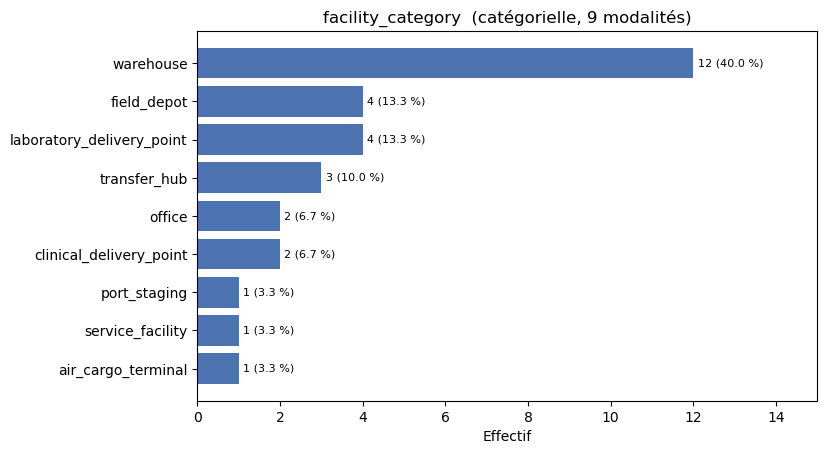


=== region  [catégorielle] ===
  Effectif : 30  (manquants : 0, modalités : 5)
  Mode : Valenne Central District (26.7 %)
                                      effectif     %
region                                              
Valenne Central District                     8  26.7
Tembara Coastal Cluster                      7  23.3
Kintara Karst Cluster                        6  20.0
Eastern Avelora Agricultural Cluster         6  20.0
Nordhaven Maritime District                  3  10.0


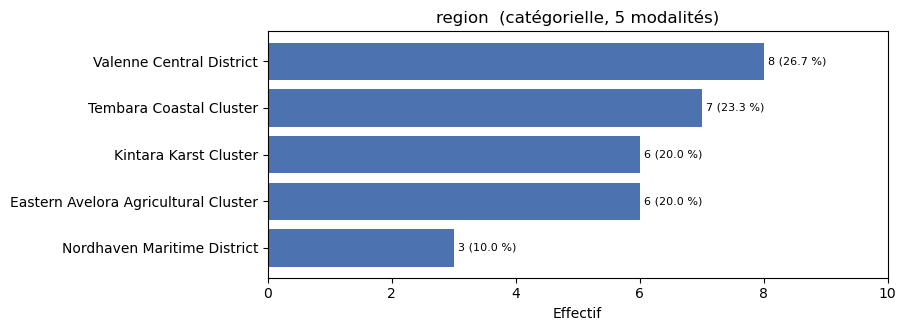


=== storage_capabilities  [catégorielle] ===
  Effectif : 30  (manquants : 0, modalités : 5)
  Mode : ambient;secure_cage (30.0 %)
                                 effectif     %
storage_capabilities                           
ambient;secure_cage                     9  30.0
ambient;secure_cage;2-8C;frozen         8  26.7
ambient                                 6  20.0
2-8C;controlled_access                  6  20.0
aucune                                  1   3.3


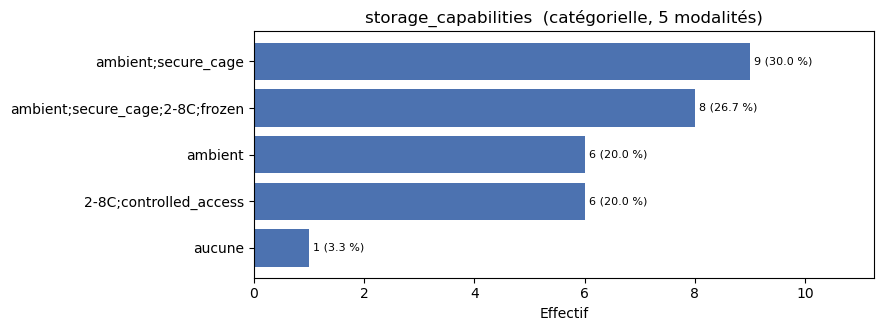


=== role_exploitant  [catégorielle] ===
  Effectif : 30  (manquants : 0, modalités : 5)
  Mode : carrier (33.3 %)
                   effectif     %
role_exploitant                  
carrier                  10  33.3
customer                  9  30.0
supplier                  6  20.0
supplier_customer         4  13.3
service_partner           1   3.3


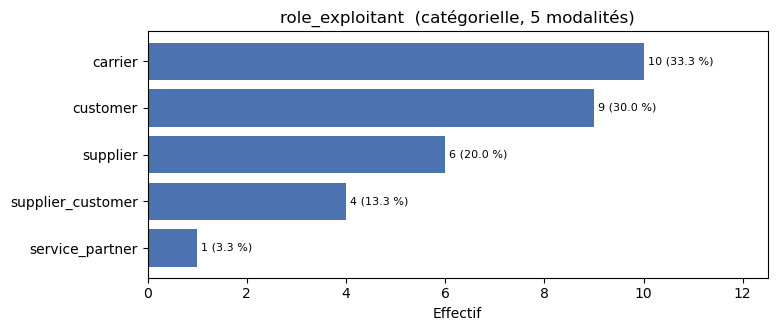


=== latitude  [continue] ===
  Effectif : 30  (manquants : 0, valeurs distinctes : 30)
  Moyenne ± écart-type : 21.176 ± 22.289
  Médiane [min ; Q1 - Q3 ; max] : 7.393 [2.099 ; 4.651 - 47.230 ; 56.529]
  Asymétrie : 0.61


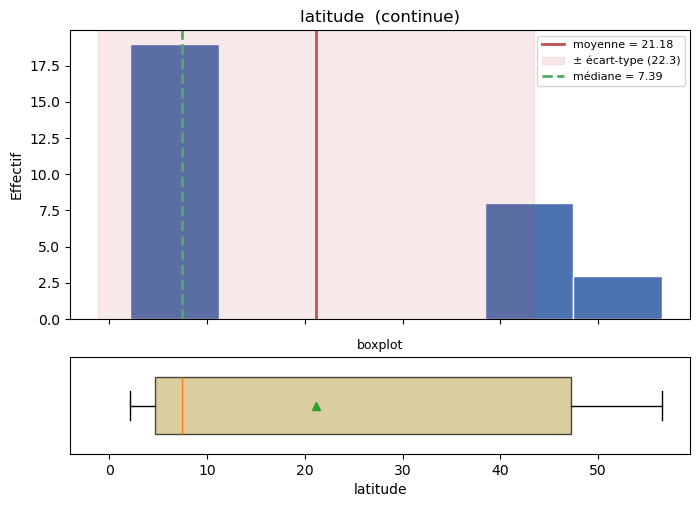


=== longitude  [continue] ===
  Effectif : 30  (manquants : 0, valeurs distinctes : 30)
  Moyenne ± écart-type : 70.116 ± 48.244
  Médiane [min ; Q1 - Q3 ; max] : 101.909 [7.490 ; 8.071 - 104.541 ; 112.391]
  Asymétrie : -0.57


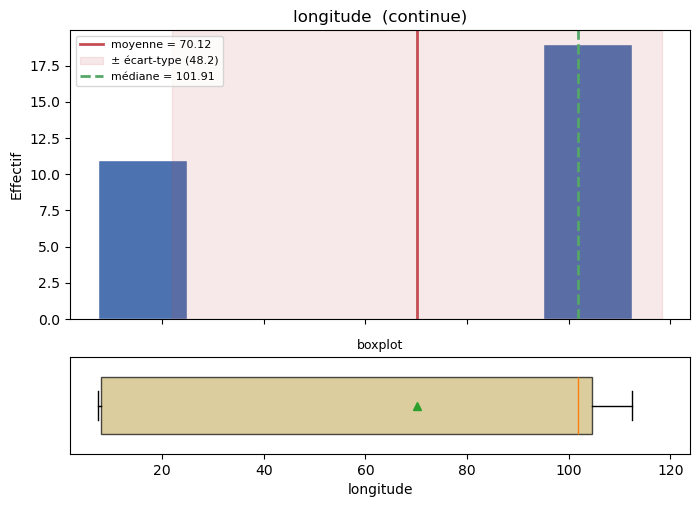


=== opening_date  [date] ===
  Effectif : 30  (manquants : 0, valeurs distinctes : 16)
  Moyenne ± écart-type : 2006-02-06 ± 1973.5 jours
  Médiane [min ; Q1 - Q3 ; max] : 2007-01-01 [1996-01-01 ; 2002-04-02 - 2010-01-01 ; 2015-01-01]
  Asymétrie : -0.40


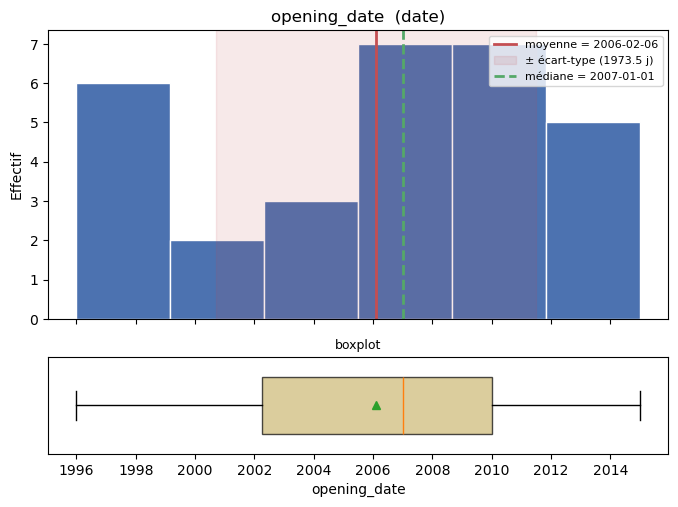


=== nb_capacites  [discrète] ===
  Effectif : 30  (manquants : 0, valeurs distinctes : 4)
  Moyenne ± écart-type : 2.267 ± 1.172
  Médiane [min ; Q1 - Q3 ; max] : 2.000 [0.000 ; 2.000 - 3.500 ; 4.000]
  Asymétrie : 0.40


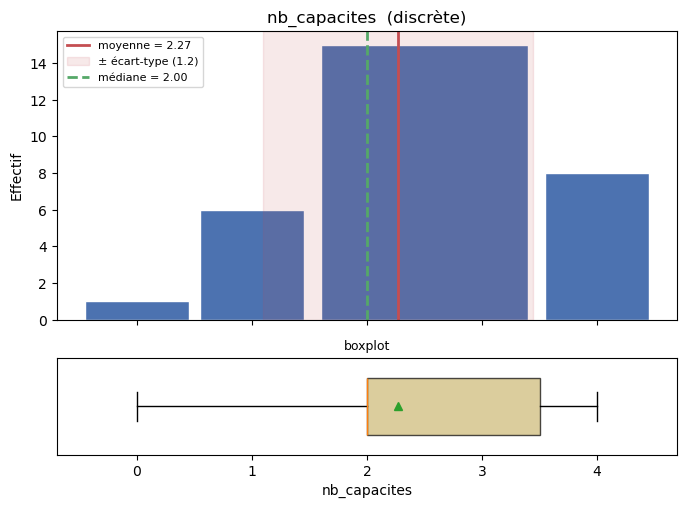


=== nb_receptions  [discrète] ===
  Effectif : 30  (manquants : 0, valeurs distinctes : 19)
  Moyenne ± écart-type : 20.333 ± 28.186
  Médiane [min ; Q1 - Q3 ; max] : 8.000 [2.000 ; 5.000 - 22.250 ; 133.000]
  Asymétrie : 2.73


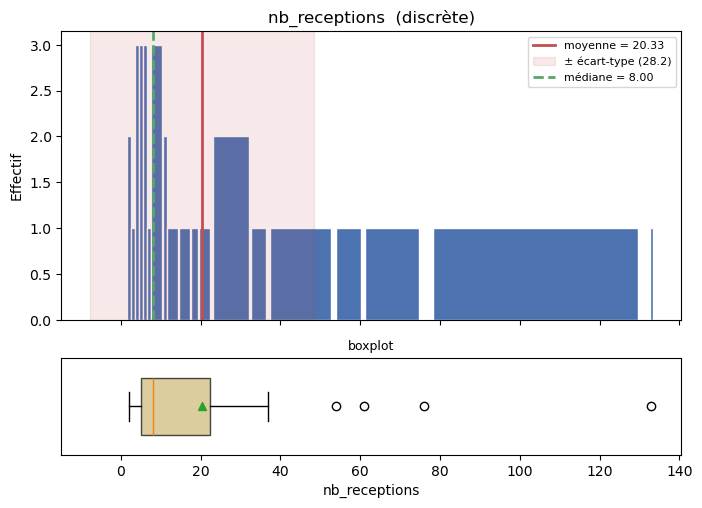

In [16]:
colonnes_univariees = ["facility_category", "region", "storage_capabilities", "role_exploitant",
                       "latitude", "longitude", "opening_date", "nb_capacites", "nb_receptions"]
resume = analyser_variables(fa, columns=colonnes_univariees)

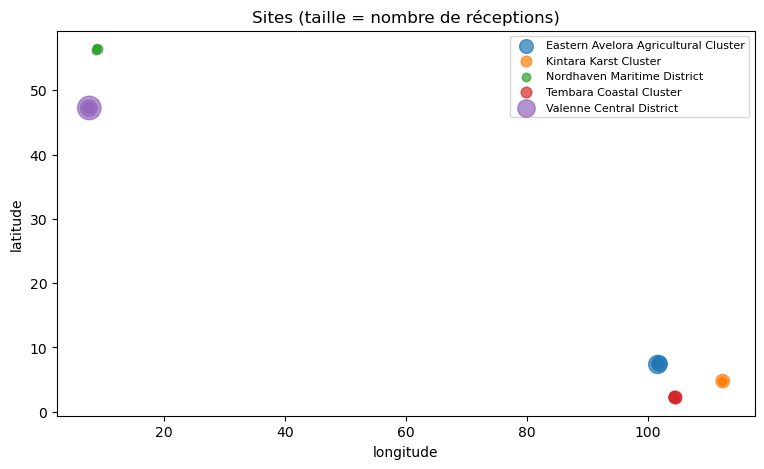

In [17]:
# Vue d'ensemble des positions (simple nuage de points ; l'analyse spatiale vient plus loin)
fig, ax = plt.subplots(figsize=(9, 5))
for region, g in fa.groupby("region"):
    ax.scatter(g.longitude, g.latitude, s=20 + 2 * g.nb_receptions, label=region, alpha=.7)
ax.set(xlabel="longitude", ylabel="latitude", title="Sites (taille = nombre de réceptions)")
ax.legend(fontsize=8)
plt.show()

Les entrepôts représentent 40 % des sites, suivis des laboratoires et des dépôts de terrain (13,3 % chacun) et des hubs (10 %). Pour les régions, Valenne a 26,7 % des sites (8), Tembara 23,3 %, Kintara et Avelora 20 % chacune, et Nordhaven seulement 10 % (3 sites). Les exploitants sont des transporteurs dans 33,3 % des cas (dont les 4 sites Meridian), des clients dans 30 % et des fournisseurs dans 20 %.

Les histogrammes des coordonnées ont deux bosses : un groupe de sites vers 47-56° N et 7-9° E (Valenne, Nordhaven) et un autre vers 2-8° N et 101-112° E (Tembara, Kintara, Avelora). La latitude moyenne (21,2) tombe pile entre les deux, là où il n'y a aucun site, ce qui montre bien pourquoi il faut regarder l'histogramme avant de se fier à la moyenne.

Les sites ont ouvert entre 1996 et 2015 (médiane 2007), aucun après 2015. Ils ont 2 capacités en médiane. Pour l'activité, la médiane est de 8 réceptions par site mais ça monte jusqu'à 133, quelques sites concentrent l'essentiel, et tous en ont reçu au moins 2.

Sur la carte, les 5 régions sont bien séparées, et les plus gros points sont à Valenne (siège Meridian, campus Asterion) et en Avelora (clinique Asterion, hub Meridian).

---
## 4. Corrélations

### 4.1 Spearman et Pearson

Variables utilisées (6) : ['latitude (numérique)', 'longitude (numérique)', 'annee_ouverture (numérique)', 'nb_capacites (numérique)', 'nb_receptions (numérique)', 'coord_precision_basse (numérique)']


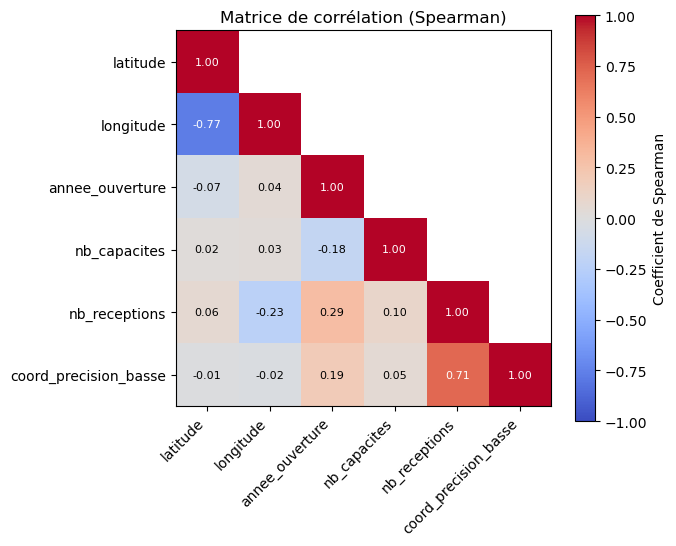


Paires avec |spearman| >= 0.4 :
           variable_1    variable_2    valeur
            longitude      latitude -0.769967
coord_precision_basse nb_receptions  0.712254


In [18]:
numeriques = ["latitude", "longitude", "annee_ouverture", "nb_capacites", "nb_receptions", "coord_precision_basse"]
spearman = matrice_correlation(fa, columns=numeriques, method="spearman", seuil_paires=0.4)

Variables utilisées (6) : ['latitude (numérique)', 'longitude (numérique)', 'annee_ouverture (numérique)', 'nb_capacites (numérique)', 'nb_receptions (numérique)', 'coord_precision_basse (numérique)']


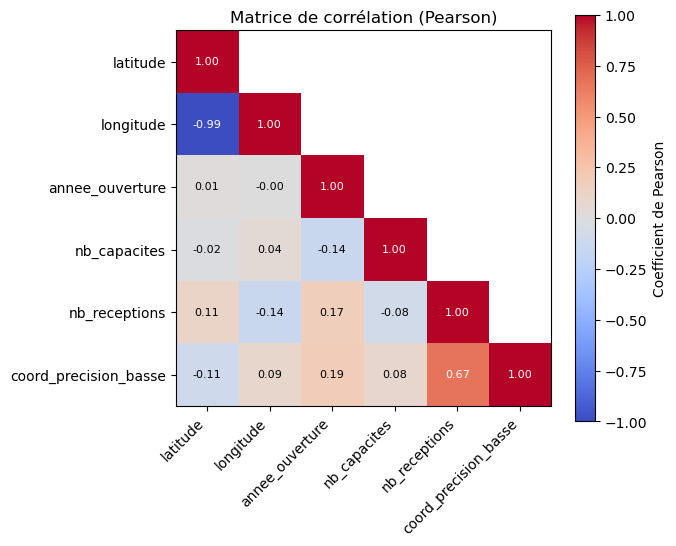


Paires avec |pearson| >= 0.4 :
           variable_1    variable_2    valeur
            longitude      latitude -0.988410
coord_precision_basse nb_receptions  0.667675


In [19]:
pearson = matrice_correlation(fa, columns=numeriques, method="pearson", seuil_paires=0.4)

Paires où Spearman et Pearson diffèrent de plus de 0,15 :
  latitude - longitude : Spearman -0.77 | Pearson -0.99
  nb_capacites - nb_receptions : Spearman 0.10 | Pearson -0.08


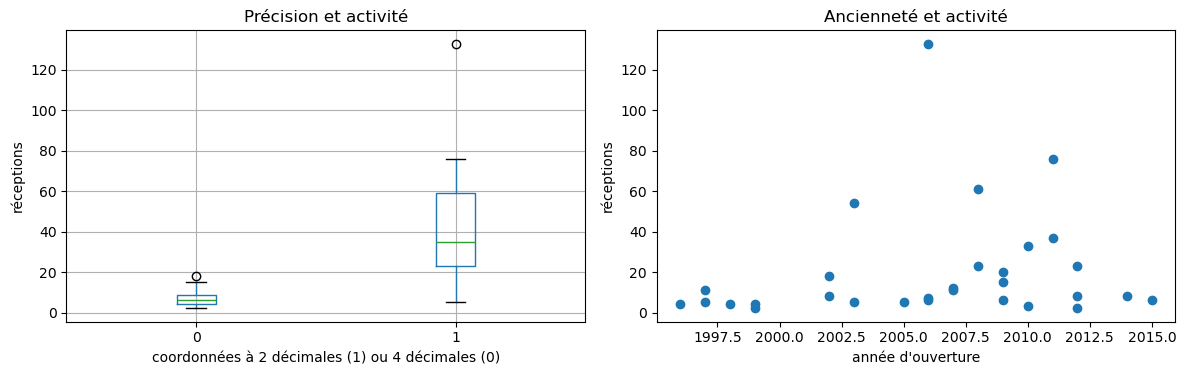

In [20]:
ecart = (spearman - pearson).abs()
print("Paires où Spearman et Pearson diffèrent de plus de 0,15 :")
for i, a in enumerate(ecart.index):
    for b in ecart.columns[i + 1:]:
        if ecart.loc[a, b] > 0.15:
            print(f"  {a} - {b} : Spearman {spearman.loc[a, b]:.2f} | Pearson {pearson.loc[a, b]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fa.boxplot(column="nb_receptions", by="coord_precision_basse", ax=axes[0])
axes[0].set(xlabel="coordonnées à 2 décimales (1) ou 4 décimales (0)", ylabel="réceptions", title="Précision et activité")
axes[1].scatter(fa.annee_ouverture, fa.nb_receptions)
axes[1].set(xlabel="année d'ouverture", ylabel="réceptions", title="Ancienneté et activité")
plt.suptitle("")
plt.tight_layout()
plt.show()

Latitude et longitude ont une corrélation de −0,99 avec Pearson et −0,77 avec Spearman. Ce n'est pas un vrai lien : il y a juste deux paquets de sites très éloignés l'un de l'autre, et Pearson est gonflé par ces deux paquets. La corrélation décrit la géographie, pas un mécanisme.

La corrélation la plus intéressante est entre « coordonnées à 2 décimales » et nombre de réceptions (Spearman 0,71, Pearson 0,67) : les sites à 2 décimales reçoivent beaucoup plus (médiane 35 contre 6). Évidemment la précision des coordonnées ne cause pas l'activité, les deux viennent du groupe d'organisations auquel appartient le site. L'année d'ouverture et le nombre de capacités ne sont liés à rien.

### 4.2 Liens entre catégories 

Variables catégorielles utilisées (5) : ['facility_category', 'region', 'storage_capabilities', 'role_exploitant', 'reg_serie_exploitant']


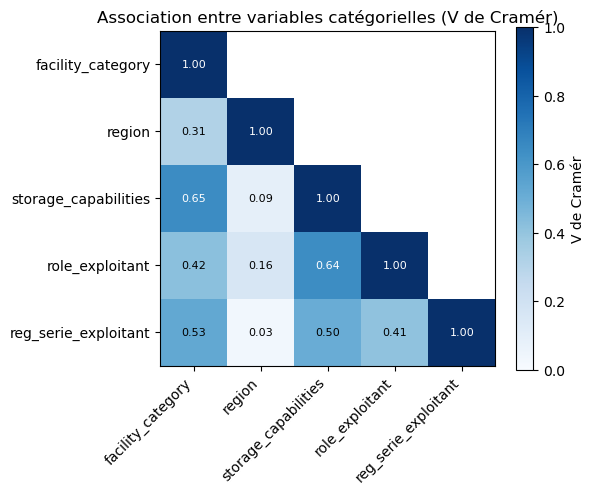


Paires avec |V de Cramér| >= 0.5 :
          variable_1           variable_2   valeur
storage_capabilities    facility_category 0.647895
     role_exploitant storage_capabilities 0.643552
reg_serie_exploitant    facility_category 0.527290
reg_serie_exploitant storage_capabilities 0.504608


In [21]:
nominales = ["facility_category", "region", "storage_capabilities", "role_exploitant", "reg_serie_exploitant"]
cramer = matrice_cramer(fa, columns=nominales)

Le type de site décide de ses capacités (V = 0,65). Les entreprises de la série 01 exploitent surtout des bureaux, hubs et cliniques, pas des entrepôts.

---
## 5. Regrouper les sites

### 5.1 Profil de chaque site

La table dit ce qu'un site est (catégorie, région, capacités, exploitant). Pour savoir ce qu'il fait, on ajoute son activité calculée à partir des autres tables : réceptions et nombre de fournisseurs, expéditions entrantes et sortantes, part des expéditions reçues sous froid, sous autorisation restreinte ou d'urgence, part d'échantillons biologiques, et nombre de corrections de stock. Dans ces tables on fait juste le nettoyage minimum.

Dans toute cette partie, la question qu'on se pose est de savoir si le groupe des 10 (les sites à 2 décimales) est un vrai groupe.

In [22]:
def lire(nom):
    return pd.read_csv(DATA / nom, dtype=str).apply(lambda s: s.str.strip()).drop_duplicates()

def convertir_date(serie):
    # formats rencontrés dans les tables logistiques (voir le notebook des réceptions)
    out = pd.Series(pd.NaT, index=serie.index)
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%d/%m/%Y", "%d-%b-%Y"):
        out = out.fillna(pd.to_datetime(serie, format=fmt, errors="coerce"))
    return out

sh = lire("shipments.csv").drop_duplicates("shipment_number")
for c in ["temperature_control_class", "authorization_class", "shipment_status", "item_category"]:
    sh[c] = sh[c].str.lower()
sh["declared_purpose"] = sh.declared_purpose.str.lower().str.split().str.join(" ")
sh["dispatch_time"] = pd.to_datetime(sh.dispatch_time, format="%Y-%m-%dT%H:%M:%S", errors="coerce").fillna(
    pd.to_datetime(sh.dispatch_time, format="%d-%b-%Y %H:%M:%S", errors="coerce"))
rc = lire("goods_receipts.csv").drop_duplicates("receipt_number")
rc["receipt_date"] = convertir_date(rc.receipt_date)
po = lire("purchase_order_lines.csv")
rc = rc.merge(po[["purchase_order_number", "item_category"]].assign(item_category=po.item_category.str.lower()),
              on="purchase_order_number", how="left")
adj = lire("inventory_adjustments.csv")
adj["adjustment_date"] = convertir_date(adj.adjustment_date)
print(f"Expéditions : {len(sh)} | réceptions : {len(rc)} | ajustements : {len(adj)}")
print("Dates illisibles :", int(sh.dispatch_time.isna().sum()), int(rc.receipt_date.isna().sum()),
      int(adj.adjustment_date.isna().sum()))

GROUPE10 = fa.loc[fa.coord_precision_basse == 1, "facility_code"].tolist()
fa["groupe10"] = fa.coord_precision_basse
dest, orig = sh.destination_facility_code, sh.origin_facility_code
fa = fa.set_index("facility_code")
fa["nb_fournisseurs"] = rc.groupby("receiving_facility_code").supplier_partner_code.nunique()
fa["nb_exp_entrantes"] = dest.value_counts()
fa["nb_exp_sortantes"] = orig.value_counts()
fa["part_froid_entrant"] = sh.temperature_control_class.isin(["2-8c", "frozen"]).groupby(dest).mean()
fa["part_sensible_entrant"] = sh.authorization_class.isin(["restricted", "emergency"]).groupby(dest).mean()
fa["part_bio_entrant"] = sh.item_category.eq("biological_sample").groupby(dest).mean()
fa["nb_ajustements"] = adj.facility_code.value_counts()
activite = ["nb_receptions", "nb_fournisseurs", "nb_exp_entrantes", "nb_exp_sortantes", "nb_ajustements"]
parts = ["part_froid_entrant", "part_sensible_entrant", "part_bio_entrant"]
fa[activite + parts] = fa[activite + parts].fillna(0)
fa = fa.reset_index()
print()
print(fa.groupby("groupe10")[activite + parts].median().rename(index={0: "20 autres", 1: "groupe des 10"}).round(2).T.to_string())

Expéditions : 450 | réceptions : 610 | ajustements : 140
Dates illisibles : 2 0 0

groupe10               20 autres  groupe des 10
nb_receptions               6.00          35.00
nb_fournisseurs             6.00          21.50
nb_exp_entrantes            5.50          22.50
nb_exp_sortantes            6.00          26.50
nb_ajustements              3.00           5.50
part_froid_entrant          0.16           0.21
part_sensible_entrant       0.18           0.18
part_bio_entrant            0.00           0.11


### 5.2 Une distance pour chaque type de colonne

On a trois types de colonnes, donc on utilise trois distances qu'on moyenne avec le même poids :

| Bloc | Colonnes | Distance | Pourquoi |
|---|---|---|---|
| Capacités | 5 colonnes 0/1 | Jaccard | deux sites qui n'ont pas de congélateur ne se ressemblent pas pour autant : Jaccard ignore les absences communes alors que Hamming les compterait comme une ressemblance |
| Nature | catégorie, région, rôle de l'exploitant | Hamming | catégories sans ordre |
| Activité | 5 comptages (en log, car quelques sites écrasent les autres) et 3 parts, centrés-réduits | euclidienne, ramenée entre 0 et 1 | nombres |

On a fait exprès de ne pas utiliser la précision des coordonnées ni la série de l'exploitant. Comme ça, si on retrouve quand même le groupe des 10, c'est que ces sites se distinguent par ce qu'ils sont ou ce qu'ils font, et pas par un détail de format.

In [23]:
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler

caps = [c for c in fa.columns if c.startswith("cap_")]
Xact = pd.concat([np.log1p(fa[activite]), fa[parts]], axis=1)
Xact = pd.DataFrame(StandardScaler().fit_transform(Xact), columns=Xact.columns, index=fa.facility_code)
D_cap = np.nan_to_num(squareform(pdist(fa[caps].astype(bool).values, "jaccard")))
D_nom = squareform(pdist(fa[["facility_category", "region", "role_exploitant"]].apply(
    lambda s: s.astype("category").cat.codes), "hamming"))
D_act = squareform(pdist(Xact, "euclidean")); D_act = D_act / D_act.max()
D = (D_cap + D_nom + D_act) / 3

codes = fa.facility_code.values
iu = np.triu_indices(len(D), 1)
paires = pd.Series(D[iu], index=pd.MultiIndex.from_arrays([codes[iu[0]], codes[iu[1]]]))
print(f"Distance : min {D[iu].min():.3f} | médiane {np.median(D[iu]):.3f} | max {D[iu].max():.3f}")
nom = fa.set_index("facility_code").facility_name
print("\nPaires de sites les plus semblables :")
for (a, b), d in paires.nsmallest(6).items():
    print(f"  {d:.3f}  {a} {nom[a][:38]:38s} ~ {b} {nom[b][:38]}")
g = fa.groupe10.values
intra10 = D[np.ix_(g == 1, g == 1)][np.triu_indices(10, 1)].mean()
intra20 = D[np.ix_(g == 0, g == 0)][np.triu_indices(20, 1)].mean()
entre = D[np.ix_(g == 1, g == 0)].mean()
print(f"\nDistance moyenne : dans le groupe des 10 = {intra10:.3f} | entre les 20 autres = {intra20:.3f} | entre les deux = {entre:.3f}")

Distance : min 0.046 | médiane 0.644 | max 0.952

Paires de sites les plus semblables :
  0.046  FCL-1012 Valenne Laboratory Materials Store     ~ FCL-1002 Lumen Safety Equipment Store
  0.049  FCL-1014 Tembara Coastal Research Store         ~ FCL-1003 Pelagos Samples Laboratory
  0.058  FCL-1009 Nordhaven Freight Exchange Warehouse   ~ FCL-1023 North Quay Biomedical Store
  0.080  FCL-1008 Civic Health Receiving Centre          ~ FCL-1002 Lumen Safety Equipment Store
  0.086  FCL-1008 Civic Health Receiving Centre          ~ FCL-1012 Valenne Laboratory Materials Store
  0.162  FCL-1021 Kintara Emergency Logistics Depot      ~ FCL-1005 Tembara Customs Inspection Yard

Distance moyenne : dans le groupe des 10 = 0.629 | entre les 20 autres = 0.546 | entre les deux = 0.662


Le groupe des 10 se distingue surtout par le volume (35 réceptions en médiane contre 6) et reçoit 11 % d'échantillons biologiques. Par leur nature, ces sites sont très différents entre eux.

### 5.3 PCA et t-SNE

On fait la PCA sur l'activité (des nombres) pour pouvoir lire les axes, et le t-SNE sur la distance complète pour voir les voisinages. Avec 30 sites il faut une petite perplexité (8), ce qui rend le t-SNE assez fragile, donc on s'en sert seulement pour vérifier visuellement ce que montrent les autres méthodes.

Variance expliquée : [0.468 0.263 0.129 0.066] | cumul 2 axes : 0.73
                        PC1   PC2
nb_receptions          0.50 -0.07
nb_fournisseurs        0.49 -0.10
nb_exp_entrantes       0.48  0.03
nb_exp_sortantes       0.47 -0.20
nb_ajustements         0.22  0.42
part_froid_entrant     0.09  0.59
part_sensible_entrant -0.01  0.17
part_bio_entrant       0.04  0.62


c:\Users\Tech For All\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Tech For All\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Tech For All\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Tech For All\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~

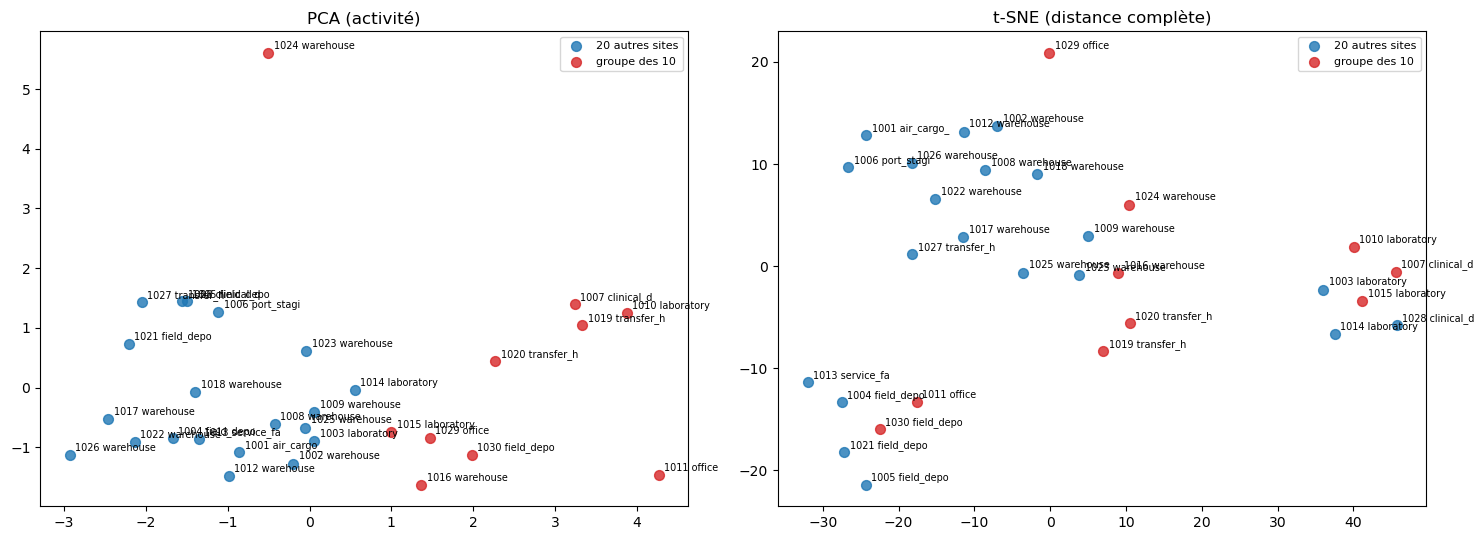

In [24]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA().fit(Xact)
print("Variance expliquée :", pca.explained_variance_ratio_[:4].round(3), "| cumul 2 axes :",
      pca.explained_variance_ratio_[:2].sum().round(3))
print(pd.DataFrame(pca.components_[:2].T, index=Xact.columns, columns=["PC1", "PC2"]).round(2).to_string())
P = pca.transform(Xact)[:, :2]
T = TSNE(2, metric="precomputed", perplexity=8, init="random", random_state=0).fit_transform(D)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, Z, titre in [(axes[0], P, "PCA (activité)"), (axes[1], T, "t-SNE (distance complète)")]:
    for v, col, lab in [(0, "tab:blue", "20 autres sites"), (1, "tab:red", "groupe des 10")]:
        m = fa.groupe10.values == v
        ax.scatter(Z[m, 0], Z[m, 1], c=col, label=lab, s=50, alpha=.8)
    for i, c in enumerate(codes):
        ax.annotate(c[-4:] + " " + fa.facility_category.iloc[i][:10], Z[i], fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.set_title(titre); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Avec la PCA, 2 axes expliquent 73 % de la variance, bien plus que pour les réceptions ou les partenaires, donc l'activité d'un site se résume bien en deux dimensions. Le premier axe correspond au volume (réceptions, fournisseurs, expéditions) et le deuxième à la spécialisation biologique et froide (échantillons biologiques, froid, corrections de stock). Le groupe des 10 est presque entièrement à droite sur le premier axe. La seule exception est `FCL-1024` (le centre d'agrégation biologique de Meridian à Kintara), tout en haut du deuxième axe, avec peu de volume mais 70 % d'échantillons biologiques.

Le t-SNE, lui, regroupe plutôt par nature : laboratoires et cliniques ensemble à droite, dépôts de terrain en bas à gauche (avec le siège `FCL-1011`), entrepôts en haut, et le groupe des 10 est éparpillé. Les deux visualisations sont donc cohérentes : par leur activité les 10 sites forment un groupe, mais par leur nature ils sont mélangés aux autres.

### 5.4 Regroupement

On utilise K-means sur l'activité, car ce sont des nombres centrés-réduits et donc la moyenne et la distance euclidienne ont un sens. Sur la distance complète (Jaccard + Hamming + euclidienne), K-means et Ward ne marchent pas, donc on prend K-medoids et le hiérarchique avec liaison moyenne, qui acceptent n'importe quelle distance. On ajoute DBSCAN, toujours sur la distance complète, parce qu'il n'oblige pas chaque site à entrer dans un groupe et montre ceux qui ne ressemblent à personne.

On choisit k avec la silhouette, puis on compare chaque résultat au groupe des 10 avec l'indice de Rand ajusté (0 = hasard, 1 = identique).

c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to 

K-means (activité)     silhouette : {2: np.float64(0.285), 3: np.float64(0.249), 4: np.float64(0.213), 5: np.float64(0.231), 6: np.float64(0.218)} -> k = 2
K-medoids (complète)   silhouette : {2: np.float64(0.263), 3: np.float64(0.268), 4: np.float64(0.355), 5: np.float64(0.389), 6: np.float64(0.354)} -> k = 5
  médoïdes : ['FCL-1011 Meridian Valenne Headquarters', 'FCL-1009 Nordhaven Freight Exchange Warehouse', 'FCL-1014 Tembara Coastal Research Store', 'FCL-1021 Kintara Emergency Logistics Depot', 'FCL-1008 Civic Health Receiving Centre']

Accord avec le groupe des 10 (ARI) :
  cl_kmeans    ARI = 0.87 | groupes : 2
  cl_kmedoids  ARI = 0.15 | groupes : 5
  cl_hier      ARI = 0.08 | groupes : 5
  cl_dbscan    ARI = 0.09 | groupes : 4
DBSCAN (eps = 0.373) : bruit = ['FCL-1011', 'FCL-1029']


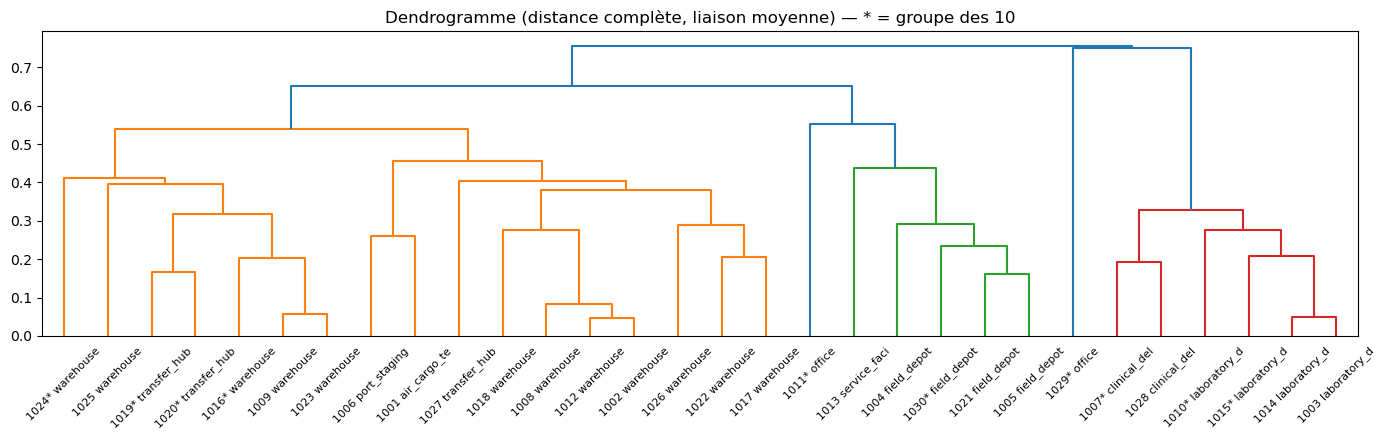

In [25]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

def k_medoids(D, k, n_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    med = rng.choice(len(D), k, replace=False)
    for _ in range(n_iter):
        lab = D[:, med].argmin(axis=1)
        nouveaux = np.array([np.where(lab == j)[0][D[np.ix_(lab == j, lab == j)].sum(axis=1).argmin()] for j in range(k)])
        if set(nouveaux) == set(med):
            break
        med = nouveaux
    return D[:, med].argmin(axis=1), med

res = {}
sil_km = {k: silhouette_score(Xact, KMeans(k, n_init=20, random_state=0).fit_predict(Xact)) for k in range(2, 7)}
k1 = max(sil_km, key=sil_km.get)
fa["cl_kmeans"] = KMeans(k1, n_init=20, random_state=0).fit_predict(Xact)
print("K-means (activité)     silhouette :", {k: round(v, 3) for k, v in sil_km.items()}, "-> k =", k1)

sil_kmed = {}
for k in range(2, 7):
    best = min((k_medoids(D, k, seed=s) for s in range(20)), key=lambda r: D[np.arange(len(D)), r[1][r[0]]].sum())
    sil_kmed[k] = (silhouette_score(D, best[0], metric="precomputed"), best)
k2 = max(sil_kmed, key=lambda k: sil_kmed[k][0])
fa["cl_kmedoids"], medoides = sil_kmed[k2][1]
print("K-medoids (complète)   silhouette :", {k: round(v[0], 3) for k, v in sil_kmed.items()}, "-> k =", k2)
print("  médoïdes :", [codes[m] + " " + nom[codes[m]] for m in medoides])

Zh = linkage(squareform(D, checks=False), method="average")
fa["cl_hier"] = fcluster(Zh, k2, criterion="maxclust")
eps = float(np.quantile(np.sort(D, axis=1)[:, 3], 0.8))
fa["cl_dbscan"] = DBSCAN(eps=eps, min_samples=3, metric="precomputed").fit_predict(D)

print("\nAccord avec le groupe des 10 (ARI) :")
for c in ["cl_kmeans", "cl_kmedoids", "cl_hier", "cl_dbscan"]:
    print(f"  {c:12s} ARI = {adjusted_rand_score(fa.groupe10, fa[c]):.2f} | groupes : {fa[c].nunique()}")
print(f"DBSCAN (eps = {eps:.3f}) : bruit = {fa.loc[fa.cl_dbscan == -1, 'facility_code'].tolist()}")

fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(Zh, labels=[c[-4:] + ("*" if g else "") + " " + cat[:12] for c, g, cat in
                       zip(codes, fa.groupe10, fa.facility_category)], leaf_font_size=8, ax=ax,
           color_threshold=Zh[-k2 + 1, 2])
ax.set_title("Dendrogramme (distance complète, liaison moyenne) — * = groupe des 10"); plt.tight_layout(); plt.show()

In [26]:
for c in ["cl_kmeans", "cl_kmedoids"]:
    print(f"--- {c}")
    prof = fa.groupby(c).agg(n=("facility_code", "size"), groupe10=("groupe10", "sum"),
                             categories=("facility_category", lambda s: s.value_counts().head(2).to_dict()),
                             receptions_med=("nb_receptions", "median"), exp_entrantes_med=("nb_exp_entrantes", "median"),
                             froid=("part_froid_entrant", "mean"), sensible=("part_sensible_entrant", "mean"),
                             bio=("part_bio_entrant", "mean"))
    print(prof.round(2).to_string())
    for k_, s_ in fa.groupby(c):
        print(f"  {k_} :", ", ".join(x[-4:] + ("*" if g_ else "") for x, g_ in zip(s_.facility_code, s_.groupe10)))

--- cl_kmeans
            n  groupe10                                     categories  receptions_med  exp_entrantes_med  froid  sensible   bio
cl_kmeans                                                                                                                       
0          19         0            {'warehouse': 10, 'field_depot': 3}             6.0                5.0   0.17      0.20  0.07
1          11        10  {'laboratory_delivery_point': 3, 'office': 2}            33.0               22.0   0.26      0.21  0.15
  0 : 1027, 1009, 1008, 1018, 1006, 1022, 1017, 1013, 1012, 1025, 1003, 1004, 1002, 1001, 1026, 1028, 1023, 1021, 1005
  1 : 1011*, 1024*, 1019*, 1020*, 1016*, 1010*, 1007*, 1030*, 1029*, 1015*, 1014
--- cl_kmedoids
              n  groupe10                                                      categories  receptions_med  exp_entrantes_med  froid  sensible   bio
cl_kmedoids                                                                                               

| Algorithme | Données | k (silhouette) | Accord avec le groupe des 10 |
|---|---|---|---|
| K-means | activité | 2 (0,285) | 0,87 |
| K-medoids | distance complète | 5 (0,389) | 0,15 |
| Hiérarchique | distance complète | 5 | 0,08 |
| DBSCAN | distance complète | 3 groupes + 2 points isolés | 0,09 |



K-means sur l'activité retrouve le groupe des 10 presque exactement (ARI 0,87) sans utiliser les coordonnées. Les autres méthodes regroupent par type de site.

---
## 6. Règles et anomalies

### 6.1 Règles d'association sur les expéditions



In [27]:
from utils.pattern_detection import itemsets_frequents, regles_association

cat = fa.set_index("facility_code").facility_category
g10 = set(GROUPE10)
items = pd.DataFrame({
    "orig": orig.map(cat).values, "dest": dest.map(cat).values,
    "orig_g10": np.where(orig.isin(g10), "oui", "non"), "dest_g10": np.where(dest.isin(g10), "oui", "non"),
    "article": sh.item_category.values, "temp": sh.temperature_control_class.values,
    "autorisation": sh.authorization_class.values, "motif": sh.declared_purpose.values})
transactions = [frozenset(f"{c}={v}" for c, v in r.items()) for r in items.to_dict("records")]
F = itemsets_frequents(transactions, min_support=0.02)
Rg = regles_association(F, min_confidence=0.5, min_lift=1.5, max_taille=3)
Rg["leverage"] = Rg.support_rel - Rg.support_rel / Rg.lift
print(f"{len(transactions)} transactions, {len(F)} itemsets fréquents, {len(Rg)} règles")
for cible in ["dest_g10=oui", "article=biological_sample", "autorisation=restricted", "autorisation=emergency"]:
    base = np.mean([cible in t for t in transactions])
    r = Rg[Rg.consequent.apply(lambda c: c == (cible,))].sort_values(["lift", "support_abs"], ascending=False)
    print(f"\nRègles -> {cible} (support de base {base:.2f}) :")
    print(r[["antecedent", "support_abs", "confiance", "lift", "leverage"]].head(6).round(2).to_string(index=False)
          if len(r) else "  aucune règle")

450 transactions, 1848 itemsets fréquents, 215 règles

Règles -> dest_g10=oui (support de base 0.72) :
  aucune règle

Règles -> article=biological_sample (support de base 0.12) :
                                                               antecedent  support_abs  confiance  lift  leverage
                  (motif=environmental and wildlife reference materials,)           18        1.0  8.65      0.04
     (dest_g10=oui, motif=environmental and wildlife reference materials)           18        1.0  8.65      0.04
     (motif=environmental and wildlife reference materials, orig_g10=oui)           18        1.0  8.65      0.04
        (motif=environmental and wildlife reference materials, temp=2-8c)           18        1.0  8.65      0.04
(dest=transfer_hub, motif=environmental and wildlife reference materials)           11        1.0  8.65      0.02
(motif=environmental and wildlife reference materials, orig=transfer_hub)           11        1.0  8.65      0.02

Règles -> autorisatio

In [28]:
print("Expéditions par origine (lignes) et destination (colonnes) :")
print(pd.crosstab(items.orig_g10, items.dest_g10, margins=True).rename(index={"oui": "du groupe 10", "non": "des 20 autres"},
      columns={"oui": "vers groupe 10", "non": "vers les 20 autres"}).to_string())
print("\nPart des expéditions vers le groupe des 10, par type d'article :")
print(items.groupby("article").dest_g10.apply(lambda s: (s == "oui").mean()).sort_values(ascending=False).round(2).to_string())

Expéditions par origine (lignes) et destination (colonnes) :
dest_g10       vers les 20 autres  vers groupe 10  All
orig_g10                                              
des 20 autres                  42              95  137
du groupe 10                   84             229  313
All                           126             324  450

Part des expéditions vers le groupe des 10, par type d'article :
article
biological_sample         0.85
medical_equipment         0.83
consulting_service        0.81
medical_consumables       0.76
agricultural_product      0.75
laboratory_material       0.74
communication_service     0.73
research_contract         0.71
transport_service         0.71
protective_equipment      0.68
refrigeration_service     0.68
cold_storage_equipment    0.68
office_supply             0.67
monitoring_equipment      0.67
other                     0.64
agricultural_equipment    0.63
legal_service             0.50
grant                     0.43


On obtient 1 848 combinaisons fréquentes et 215 règles.

Aucune règle ne mène à « destination dans le groupe des 10 », mais c'est normal : 72 % des expéditions y vont déjà, donc le lift ne peut pas dépasser 1 / 0,72 = 1,39. Le tableau croisé est plus parlant : le groupe des 10 envoie 313 expéditions sur 450 (70 %), en reçoit 324 (72 %), et 229 (51 %) vont d'un site du groupe à un autre.

Le motif « *environmental and wildlife reference materials* » donne toujours un échantillon biologique (18 expéditions, lift 8,65), et ces 18 expéditions partent toutes du groupe des 10, y arrivent toutes et voyagent toutes sous froid. Les échantillons biologiques sont d'ailleurs l'article le plus envoyé vers le groupe des 10 (85 %), alors qu'à l'opposé on trouve les subventions (43 %) et les services juridiques (50 %). Enfin, aucune règle ne mène à une autorisation restreinte ou d'urgence, qui ne s'explique par rien.

Apriori suffit ici, FP-Growth donnerait les mêmes résultats. Le lift permet de ne pas prendre pour une règle forte une conclusion qui est juste très fréquente.

### 6.2 Les capacités déclarées sont-elles respectées ?



In [29]:
capf = fa.set_index("facility_code")[caps].astype(bool)
froid = sh.temperature_control_class.eq("2-8c")
congele = sh.temperature_control_class.eq("frozen")
for cote, col in [("destination", dest), ("origine", orig)]:
    ok_froid = col.map(capf.cap_2_8c | capf.cap_frozen)
    ok_cong = col.map(capf.cap_frozen)
    viol = sh[(froid & ~ok_froid) | (congele & ~ok_cong)]
    print(f"Expéditions sous froid / congelées dont le site de {cote} n'a pas la capacité : {len(viol)} "
          f"sur {int((froid | congele).sum())}")
    if len(viol):
        t = viol.groupby(col.name).agg(n=("shipment_number", "size"),
                                       articles=("item_category", lambda s: s.value_counts().head(3).to_dict()))
        t["site"] = t.index.map(nom); t["capacites"] = t.index.map(fa.set_index("facility_code").storage_capabilities)
        t["groupe10"] = t.index.isin(g10)
        print(t.sort_values("n", ascending=False).to_string())
    print()
bio = sh[sh.item_category.eq("biological_sample")]
print("Échantillons biologiques expédiés :", len(bio), "| vers un site du groupe des 10 :", int(bio.destination_facility_code.isin(g10).sum()))
print(bio.destination_facility_code.map(lambda c: f"{c} {nom[c]}").value_counts().to_string())
print("\nMotifs déclarés des échantillons biologiques :", bio.declared_purpose.value_counts().to_dict())
print("Origine des échantillons biologiques :", bio.origin_facility_code.map(lambda c: f"{c} {nom[c][:30]}").value_counts().head(5).to_dict())

Expéditions sous froid / congelées dont le site de destination n'a pas la capacité : 29 sur 107
                           n                                                                       articles                                 site               capacites  groupe10
destination_facility_code                                                                                                                                                         
FCL-1011                   9  {'medical_consumables': 5, 'biological_sample': 3, 'agricultural_product': 1}        Meridian Valenne Headquarters                 ambient      True
FCL-1030                   4                             {'medical_consumables': 3, 'biological_sample': 1}   Kintara Cave Authority Field Depot                 ambient      True
FCL-1029                   4                          {'medical_consumables': 3, 'agricultural_product': 1}         Vale Strategy Valenne Office                  aucune      True
FCL-1013 

66 % des expéditions sous froid partent d'un site sans froid, dont 43 du siège de Meridian (un bureau). Le bureau de Vale Strategy, sans stockage, en reçoit 4.

### 6.3 Sites atypiques et inventaires incohérents

On regarde d'abord les sites, avec LOF sur la distance complète (qui repère les sites dans une zone peu dense) et Isolation Forest sur l'activité et les capacités (qui isole les combinaisons rares). Avec 30 sites, on prend 5 voisins.

Ensuite on regarde les inventaires mensuels (5 sites × 5 catégories). Un stock doit vérifier une égalité simple : stock d'ouverture + reçu − sorti − usage interne − pertes = stock de clôture. L'écart correspond à ce qui a disparu (ou est apparu) sans explication. On vérifie aussi qu'on ne sort jamais plus que ce qu'on a en stock.

In [30]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest

lof = LocalOutlierFactor(n_neighbors=5, metric="precomputed").fit(D)
fa["lof"] = -lof.negative_outlier_factor_
Xif = pd.concat([Xact.reset_index(drop=True), fa[caps].reset_index(drop=True)], axis=1)
fa["iforest"] = -IsolationForest(n_estimators=500, random_state=0).fit(Xif).score_samples(Xif)
fa["rang_lof"] = fa.lof.rank(ascending=False); fa["rang_iforest"] = fa.iforest.rank(ascending=False)
top = fa[(fa.rang_lof <= 5) | (fa.rang_iforest <= 5)].sort_values("rang_lof")
print(top[["facility_code", "facility_name", "facility_category", "groupe10", "nb_receptions", "nb_exp_entrantes",
           "part_bio_entrant", "lof", "rang_lof", "rang_iforest"]].round(2).to_string(index=False))
print("Corrélation de Spearman entre les deux scores :", round(fa.lof.corr(fa.iforest, method="spearman"), 2))

facility_code                                    facility_name         facility_category  groupe10  nb_receptions  nb_exp_entrantes  part_bio_entrant  lof  rang_lof  rang_iforest
     FCL-1029                     Vale Strategy Valenne Office                    office         1             20              23.0              0.00 1.76       1.0           9.0
     FCL-1011                    Meridian Valenne Headquarters                    office         1            133              50.0              0.06 1.23       2.0           3.0
     FCL-1006                  Tembara Port Consolidation Yard              port_staging         0              7               5.0              0.20 1.12       3.0          23.0
     FCL-1001                         Nacre Air Cargo Terminal        air_cargo_terminal         0              8               8.0              0.00 1.09       4.0          29.0
     FCL-1027              Valenne Central Distribution Centre              transfer_hub         0       

In [31]:
inv = lire("inventory_month_end.csv")
quant = ["opening_stock", "received_quantity", "outgoing_quantity", "documented_internal_use", "documented_waste", "closing_stock"]
mal = {c: int((~inv[c].str.fullmatch(r"-?\d+(\.\d+)?")).sum()) for c in quant}
print("Valeurs mal formées (unité collée, virgule décimale) :", mal)
for c in quant:
    inv[c] = pd.to_numeric(inv[c].str.replace(",", ".").str.extract(r"(-?[\d.]+)")[0])
inv["reporting_month"] = pd.to_datetime(inv.reporting_month, format="%Y-%m-%d")
inv["item_category"] = inv.item_category.str.lower()
inv["ecart"] = (inv.opening_stock + inv.received_quantity - inv.outgoing_quantity
                - inv.documented_internal_use - inv.documented_waste - inv.closing_stock).round(2)
inv["sortie_impossible"] = inv.outgoing_quantity > inv.opening_stock + inv.received_quantity + 0.01
print(f"{len(inv)} lignes ; équation vérifiée (|écart| <= 0,01) : {int((inv.ecart.abs() <= .01).sum())}")
bilan = inv.groupby(["facility_code", "item_category"]).agg(
    recu=("received_quantity", "sum"), disparu=("ecart", "sum"), sorties_impossibles=("sortie_impossible", "sum"))
bilan["disparu_sur_recu"] = bilan.disparu / bilan.recu
print("\nQuantité disparue sans justification, en part de la quantité reçue (positif = perte inexpliquée) :")
print(bilan.disparu_sur_recu.unstack().round(2).to_string())
print("\nSorties supérieures au stock disponible :")
print(bilan.sorties_impossibles.unstack().to_string())
med = inv.groupby("item_category").ecart.transform("median")
mad = inv.groupby("item_category").ecart.transform(lambda s: (s - s.median()).abs().median())
inv["z_mod"] = 0.6745 * (inv.ecart - med) / mad
print("\nMois dont l'écart a un z-score modifié > 3,5 (par catégorie) :")
print(inv[inv.z_mod.abs() > 3.5].assign(reporting_month=lambda d: d.reporting_month.dt.strftime("%Y-%m")).sort_values("z_mod", ascending=False)[["facility_code", "item_category", "reporting_month",
      "opening_stock", "received_quantity", "outgoing_quantity", "closing_stock", "ecart", "z_mod"]].round(2).head(10).to_string(index=False))

Valeurs mal formées (unité collée, virgule décimale) : {'opening_stock': 4, 'received_quantity': 3, 'outgoing_quantity': 3, 'documented_internal_use': 0, 'documented_waste': 2, 'closing_stock': 4}
500 lignes ; équation vérifiée (|écart| <= 0,01) : 3

Quantité disparue sans justification, en part de la quantité reçue (positif = perte inexpliquée) :
item_category  agricultural_product  biological_sample  medical_consumables  monitoring_equipment  protective_equipment
facility_code                                                                                                          
FCL-1010                      -0.11              -0.12                 0.12                  0.01                 -1.58
FCL-1019                      -0.06               0.44                -0.05                  0.02                  0.03
FCL-1020                      -0.49               0.45                -0.68                  0.08                 -0.00
FCL-1024                      -0.14              -

LOF et Isolation Forest ne sont pas d'accord, sauf sur le siège de Meridian. Côté stocks, 42 à 45 % des échantillons biologiques reçus disparaissent à 3 sites, et `FCL-1024` expédie plus qu'il n'a.

---
## 7. Réseau et processus

### 7.1 Le réseau des sites

On construit un graphe avec un nœud par site et un lien du site d'origine vers le site de destination, pondéré par le nombre d'expéditions. On regarde qui envoie, qui reçoit, et comment le groupe des 10 est relié au reste.

In [32]:
import networkx as nx

flux = sh.groupby(["origin_facility_code", "destination_facility_code"]).size()
G = nx.DiGraph(); G.add_nodes_from(codes)
for (a, b), w in flux.items():
    G.add_edge(a, b, weight=int(w))
N, L = G.number_of_nodes(), G.number_of_edges()
print(f"N = {N}, L = {L}, densité = {L / (N * (N - 1)):.3f}")
boucles = {a: G[a][a]["weight"] for a, b in G.edges if a == b}
print(f"Boucles (un site qui s'expédie à lui-même) : {boucles} | total {sum(boucles.values())} expéditions"
      f" | sites du groupe des 10 : {sum(a in set(GROUPE10) for a in boucles)} / {len(boucles)}")
deg = pd.DataFrame({"sortant": dict(G.out_degree()), "entrant": dict(G.in_degree()),
                    "force_sortante": dict(G.out_degree(weight="weight")), "force_entrante": dict(G.in_degree(weight="weight"))})
deg["site"] = deg.index.map(nom); deg["groupe10"] = deg.index.isin(g10)
print(deg.sort_values("force_entrante", ascending=False).head(8).to_string())
print("\nSources pures :", [n for n in G if G.in_degree(n) == 0 and G.out_degree(n) > 0],
      "| puits purs :", [n for n in G if G.out_degree(n) == 0 and G.in_degree(n) > 0])
print("\nLiens les plus lourds :")
for (a, b), w in flux.sort_values(ascending=False).head(8).items():
    print(f"  {w:3d}  {a} {nom[a][:34]:34s} -> {b} {nom[b][:34]}")

N = 30, L = 234, densité = 0.269
Boucles (un site qui s'expédie à lui-même) : {'FCL-1011': 2, 'FCL-1019': 7, 'FCL-1020': 4, 'FCL-1016': 3, 'FCL-1010': 3, 'FCL-1030': 1, 'FCL-1015': 2} | total 22 expéditions | sites du groupe des 10 : 7 / 7
          sortant  entrant  force_sortante  force_entrante                                site  groupe10
FCL-1007       10       11              19              56   Asterion Avelora Executive Clinic      True
FCL-1010       18       18              37              54    Asterion Central Clinical Campus      True
FCL-1011       16       20             100              50       Meridian Valenne Headquarters      True
FCL-1019       12       13              39              48     Meridian Avelora Transfer Annex      True
FCL-1029       12       14              21              23        Vale Strategy Valenne Office      True
FCL-1030       14       16              30              22  Kintara Cave Authority Field Depot      True
FCL-1020       18       1

Betweenness (5 premiers) : {'FCL-1010': 0.122, 'FCL-1030': 0.088, 'FCL-1020': 0.066, 'FCL-1016': 0.048, 'FCL-1011': 0.047}
PageRank pondéré (5 premiers) : {'FCL-1011': 0.107, 'FCL-1010': 0.097, 'FCL-1019': 0.09, 'FCL-1007': 0.067, 'FCL-1030': 0.056}

Louvain : 4 communautés, Q = 0.191
ARI communautés / région : -0.02 | / groupe des 10 : 0.02
  C0 (5 sites, groupe des 10 : 2, régions : {'Kintara': 2, 'Eastern': 1, 'Nordhaven': 1, 'Tembara': 1}) : 1003, 1013, 1017, 1024, 1030
  C1 (7 sites, groupe des 10 : 4, régions : {'Valenne': 3, 'Eastern': 3, 'Tembara': 1}) : 1002, 1005, 1007, 1010, 1011, 1019, 1028
  C2 (10 sites, groupe des 10 : 2, régions : {'Tembara': 3, 'Kintara': 3, 'Valenne': 2, 'Eastern': 1, 'Nordhaven': 1}) : 1001, 1004, 1009, 1012, 1014, 1015, 1020, 1021, 1022, 1027
  C3 (8 sites, groupe des 10 : 2, régions : {'Valenne': 3, 'Tembara': 2, 'Eastern': 1, 'Kintara': 1, 'Nordhaven': 1}) : 1006, 1008, 1016, 1018, 1023, 1025, 1026, 1029


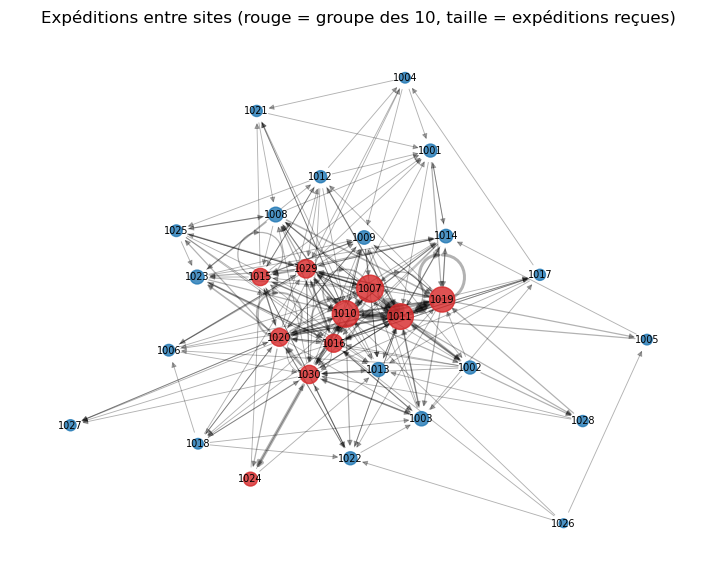

In [33]:
H = nx.Graph()
H.add_nodes_from(codes)
for a, b, d in G.edges(data=True):
    if a != b:
        w = H[a][b]["weight"] + d["weight"] if H.has_edge(a, b) else d["weight"]
        H.add_edge(a, b, weight=w)
btw = pd.Series(nx.betweenness_centrality(H)).sort_values(ascending=False)
pr = pd.Series(nx.pagerank(G, weight="weight")).sort_values(ascending=False)
print("Betweenness (5 premiers) :", btw.head(5).round(3).to_dict())
print("PageRank pondéré (5 premiers) :", pr.head(5).round(3).to_dict())
comms = nx.community.louvain_communities(H, weight="weight", seed=0)
Q = nx.community.modularity(H, comms, weight="weight")
fa["communaute"] = fa.facility_code.map({n: i for i, c in enumerate(comms) for n in c})
print(f"\nLouvain : {len(comms)} communautés, Q = {Q:.3f}")
print("ARI communautés / région :", round(adjusted_rand_score(fa.region, fa.communaute), 2),
      "| / groupe des 10 :", round(adjusted_rand_score(fa.groupe10, fa.communaute), 2))
for i, c in enumerate(comms):
    s = fa[fa.communaute == i]
    print(f"  C{i} ({len(s)} sites, groupe des 10 : {int(s.groupe10.sum())}, régions : {s.region.str.split().str[0].value_counts().to_dict()}) :",
          ", ".join(x[-4:] for x in sorted(c)))
fig, ax = plt.subplots(figsize=(9, 7))
pos = nx.spring_layout(H, weight="weight", seed=3)
nx.draw_networkx_edges(G, pos, ax=ax, alpha=.3, width=[.4 + G[a][b]["weight"] / 4 for a, b in G.edges], arrowsize=8)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[40 + 6 * G.in_degree(n, weight="weight") for n in G],
                       node_color=["tab:red" if n in g10 else "tab:blue" for n in G], alpha=.8)
nx.draw_networkx_labels(G, pos, {n: n[-4:] for n in G}, font_size=7, ax=ax)
ax.set_title("Expéditions entre sites (rouge = groupe des 10, taille = expéditions reçues)"); ax.axis("off"); plt.show()

Réseau dense (densité 0,27) qui passe par le groupe des 10. 7 sites s'envoient des marchandises à eux-mêmes, tous dans le groupe des 10.

### 7.2 Comment vit un site ?

Pour chaque site, on met ses événements dans l'ordre : `reception`, `exp_entrante`, `exp_sortante` et `ajustement` (correction de stock). On fusionne les répétitions, on compte les enchaînements et on calcule la dépendance de l'Heuristic Miner, qui gère bien les données désordonnées contrairement à l'Alpha Miner. On s'intéresse surtout à ce qui se passe juste avant une correction de stock.

In [34]:
ev = pd.concat([
    pd.DataFrame({"site": rc.receiving_facility_code, "t": rc.receipt_date, "activite": "reception"}),
    pd.DataFrame({"site": dest, "t": sh.dispatch_time, "activite": "exp_entrante"}),
    pd.DataFrame({"site": orig, "t": sh.dispatch_time, "activite": "exp_sortante"}),
    pd.DataFrame({"site": adj.facility_code, "t": adj.adjustment_date, "activite": "ajustement"})]).dropna()
ev = ev.sort_values(["site", "t", "activite"])
traces = ev.groupby("site").activite.apply(lambda s: [a for i, a in enumerate(s) if i == 0 or a != s.iloc[i - 1]])
acts = ["DEBUT", "reception", "exp_entrante", "exp_sortante", "ajustement", "FIN"]
DF = pd.DataFrame(0, index=acts, columns=acts)
for t in traces:
    t = ["DEBUT"] + t + ["FIN"]
    for a, b in zip(t, t[1:]):
        DF.loc[a, b] += 1
print(f"{len(ev)} événements, {len(traces)} sites")
print(DF.to_string())
dep = pd.DataFrame(0.0, index=acts, columns=acts)
for a in acts:
    for b in acts:
        if a != b:
            dep.loc[a, b] = (DF.loc[a, b] - DF.loc[b, a]) / (DF.loc[a, b] + DF.loc[b, a] + 1)
print("\nDépendances Heuristic Miner >= 0,5 :")
print(dep.stack()[dep.stack() >= .5].round(2).to_string())
avant = DF["ajustement"].drop(["ajustement", "FIN"])
print("\nCe qui précède directement un ajustement :", (avant / avant.sum()).round(2).to_dict())
lien = adj.related_receipt_number.notna().groupby(adj.facility_code.isin(g10)).mean()
print("Part des ajustements rattachés à une réception (non / oui groupe des 10) :", lien.round(2).to_dict())
print("Ajustements pour 10 réceptions, groupe des 10 vs autres :",
      (10 * fa.groupby("groupe10").nb_ajustements.sum() / fa.groupby("groupe10").nb_receptions.sum()).round(2).to_dict())
print("\nMotifs d'ajustement, groupe des 10 vs autres :")
print(pd.crosstab(adj.adjustment_reason.str.lower(), adj.facility_code.isin(g10)).rename(
    columns={True: "groupe10", False: "autres"}).sort_values("groupe10", ascending=False).to_string())

1646 événements, 30 sites
              DEBUT  reception  exp_entrante  exp_sortante  ajustement  FIN
DEBUT             0          8             7            12           3    0
reception         0          0           141           129          48   13
exp_entrante      0        126             0           143          42    4
exp_sortante      0        145           129             0          32    7
ajustement        0         52            38            29           0    6
FIN               0          0             0             0           0    0

Dépendances Heuristic Miner >= 0,5 :
DEBUT         reception       0.89
              exp_entrante    0.88
              exp_sortante    0.92
              ajustement      0.75
reception     FIN             0.93
exp_entrante  FIN             0.80
exp_sortante  FIN             0.88
ajustement    FIN             0.86

Ce qui précède directement un ajustement : {'DEBUT': 0.02, 'reception': 0.38, 'exp_entrante': 0.34, 'exp_sortante': 0.26}
P

Le groupe des 10 corrige moins ses stocks (1,7 pour 10 réceptions contre 4,3) et utilise des motifs médicaux (« procedure stock issue ») qu'on ne voit pas ailleurs.

---
## Synthèse

10 sites ont des coordonnées à 2 décimales. Ils sont tous liés au registre public et reçoivent 76 % des réceptions : c'est le « groupe des 10 ».

K-means sur l'activité retrouve ce groupe sans utiliser les coordonnées (ARI 0,87). C'est donc un vrai groupe, pas un simple détail de format.

Côté anomalies, 66 % des expéditions sous froid partent d'un site sans froid, et 42 à 45 % des échantillons biologiques reçus disparaissent dans 3 sites.

Dans le réseau, tout passe par le groupe des 10, et 7 de ses sites s'envoient des marchandises à eux-mêmes.

Avec 30 sites et des inventaires sur 5 sites seulement, ce sont des indices à vérifier.